In [2]:

import pandas as pd

df = pd.read_csv('metadata.csv')


#переименовал колонку 'path' на 'image_path', чтобы не пришлось менять остальной код.
df = df.rename(columns={'path': 'image_path'}) 
df['image_path'] = './data/' + df['image_path']

df.head()






,image_path,split,label,patient_id,img_num,width,height,mode,file_size
0,./data/test/CNV/CNV-1032178-1.jpeg,test,CNV,1032178,1,1024,496,L,69392
1,./data/test/CNV/CNV-1034361-1.jpeg,test,CNV,1034361,1,1024,496,L,73847
2,./data/test/CNV/CNV-1034361-2.jpeg,test,CNV,1034361,2,1024,496,L,87609
3,./data/test/CNV/CNV-1052341-1.jpeg,test,CNV,1052341,1,1024,496,L,76332
4,./data/test/CNV/CNV-1106195-1.jpeg,test,CNV,1106195,1,1024,496,L,75900


In [5]:
print(df.shape)
print(list(df.columns))
print(df.dtypes)


(109309, 9)
['image_path', 'split', 'label', 'patient_id', 'img_num', 'width', 'height', 'mode', 'file_size']
image_path      str
split           str
label           str
patient_id    int64
img_num       int64
width         int64
height        int64
mode            str
file_size     int64
dtype: object


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 109309 entries, 0 to 109308
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   image_path  109309 non-null  str  
 1   split       109309 non-null  str  
 2   label       109309 non-null  str  
 3   patient_id  109309 non-null  int64
 4   img_num     109309 non-null  int64
 5   width       109309 non-null  int64
 6   height      109309 non-null  int64
 7   mode        109309 non-null  str  
 8   file_size   109309 non-null  int64
dtypes: int64(5), str(4)
memory usage: 7.5 MB


In [7]:
df.describe().round(2)

,patient_id,img_num,width,height,file_size
count,109309.00,109309.00,109309.00,109309.00,109309.00
mean,5105292.67,43.22,695.72,497.27,65809.17
std,2946249.81,76.62,312.58,4.37,39847.43
min,1384.00,1.00,384.00,277.00,16502.00
25%,2444883.00,6.00,512.00,496.00,39314.00
50%,5091309.00,14.00,512.00,496.00,51430.00
75%,7710023.00,43.00,768.00,496.00,77769.00
max,9997680.00,813.00,1536.00,512.00,393599.00


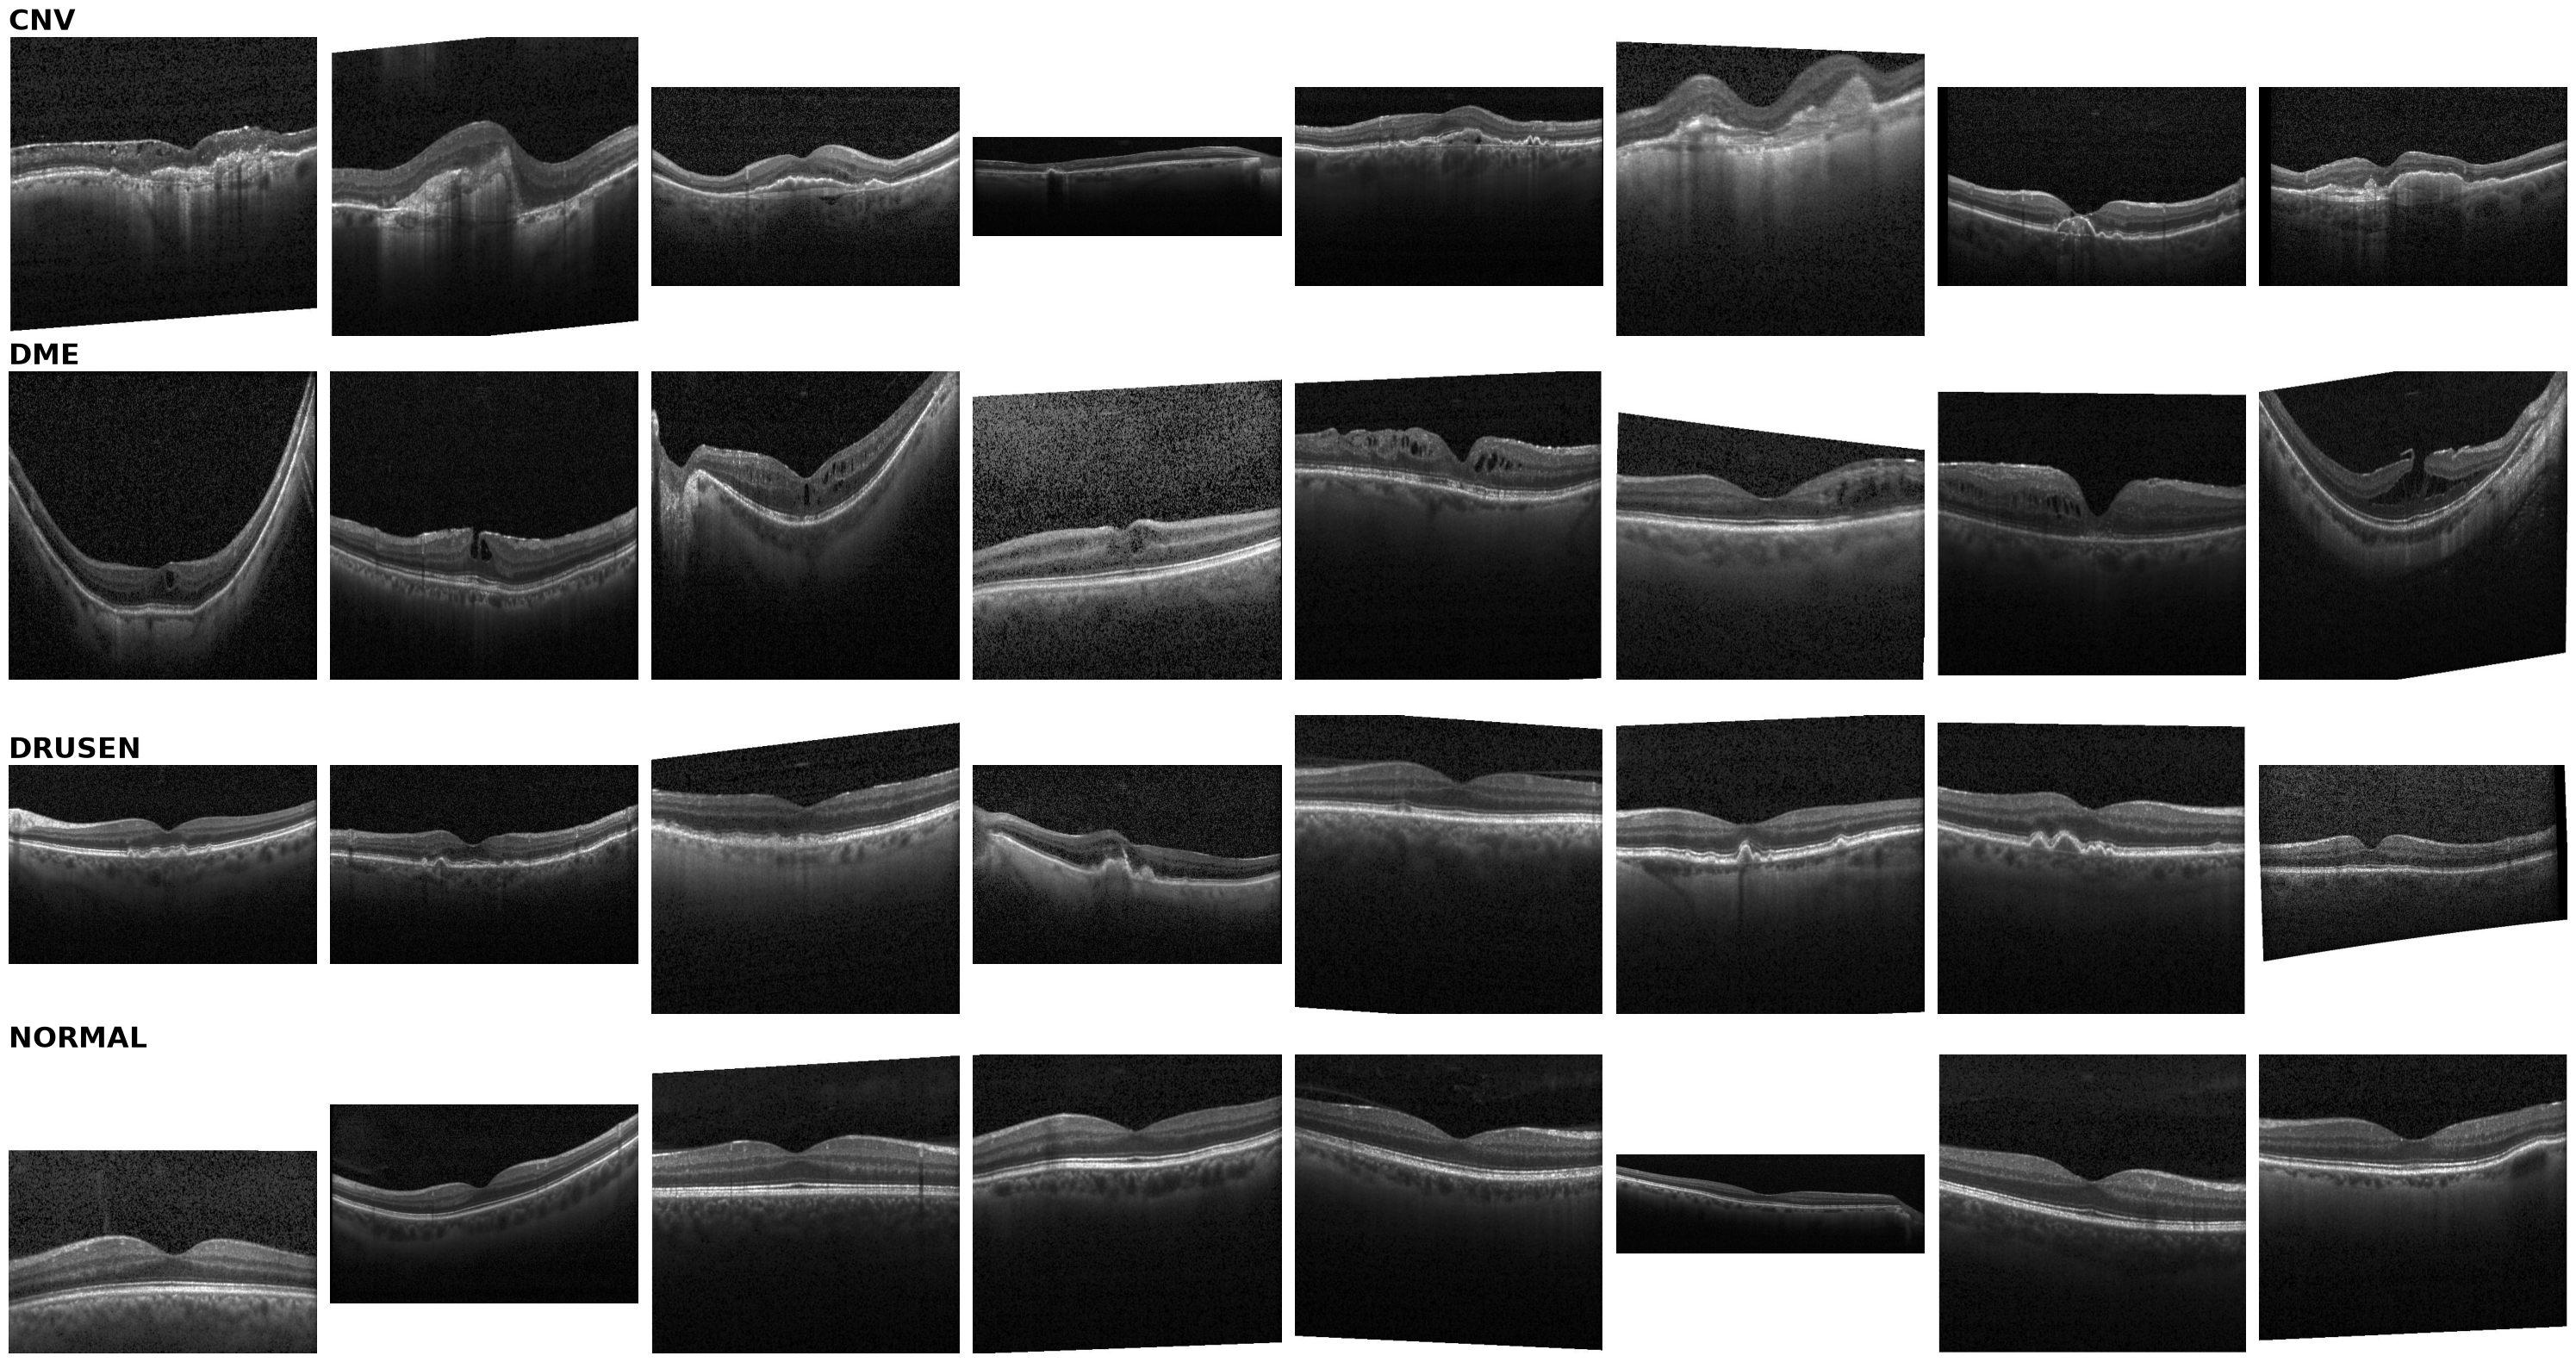

In [ ]:
#Галерея примеров по классам. Выводится 4 класса по 8 случайных снимков.

import matplotlib.pyplot as plt 

classes = df['label'].unique()

fig, ax = plt.subplots(4, 8, figsize=(30, 16))

#Идем по каждому классу, i - номер строки, clas - название класса
for i, clas in enumerate(classes):
    #оставляем только строки, которые совпадают с текущим классом и берем 8 случайных снимков
    paths = df[df['label'] == clas].sample(8)['image_path'] 

# Проходимся по 8 картинкам: n - номер колонки, path - путь к файлу
    for n, path in enumerate(paths):
        img = plt.imread(path)

        ax[i, n].imshow(img, cmap ='gray')
        ax[i, n].axis('off')

#Подписываем класс только для первой картинки в строке
        if n == 0:
                ax[i, n].set_title(clas, fontweight='bold', fontsize=24, loc='left')

plt.tight_layout()
plt.show()  
    

               



На представленных снимках в галереи можем отчетливо обозначить каждый класс:

*CNV(хориоидальная неоваскуляризация) - Деформированная и не упорядоченная структура сетчатки, полный хаос.

*DME(диабетический макулярный отек) - Сетчатка разбухшая, в центральных слоях видим темные кисты, которые могут быть от маленьких до больших размером. 

*DRUSEN(друзы) - под пигментным эпителием(это самая яркая линия на картинке) в некоторых отрезках видны бугорки, который выпячивают этот слой сетчатки.

*NORMAL - ровные, четко различимые слои сетчатки глаза.


In [4]:
#Смотрим, есть ли битые файлы
import cv2

widths = []
heights = []
channels = []
broken_files = []

#проходим по каждому пути 
for p in df['image_path']: 
    try:
        img = cv2.imread(p) #пытаемся открыть картинку с диска

        if img is None:
           raise ValueError("Битый файл") #если картинка не открылась, вызывваем ошибку

        h, w = img.shape[:2] #если картинка открылась, берем высоту и ширину
        
        if len(img.shape) == 2: #если в размерах картинки 2 числа(высота и ширина)
            c = 1 # 1 канал - черно-белая картинка
        else:
            c = img.shape[2] #берется 3 число(количество каналов)

        widths.append(w)
        heights.append(h)
        channels.append(c)
        broken_files.append(False)

    except Exception:     
       widths.append(None)
       heights.append(None)
       channels.append(None)
       broken_files.append(True)


#добавляем новые колонки в таблицу df
df['width'] = widths
df['height'] = heights
df['channels'] = channels
df['broken_files'] = broken_files

print(f"Битых файлов: {df['broken_files'].sum()}")

Битых файлов: 0


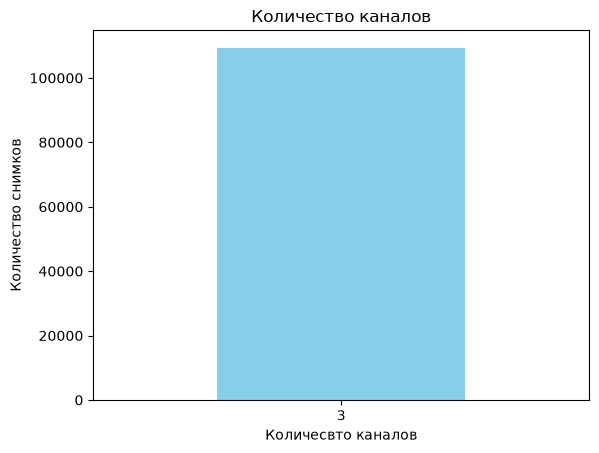

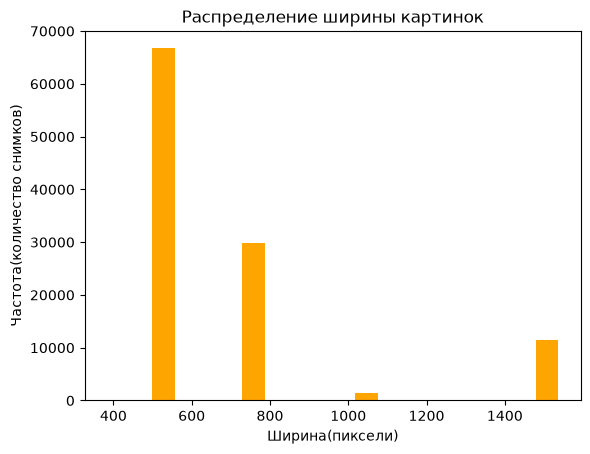

width
512     66696
768     29749
1536    11512
1024     1329
384        21
642         1
900         1
Name: count, dtype: int64


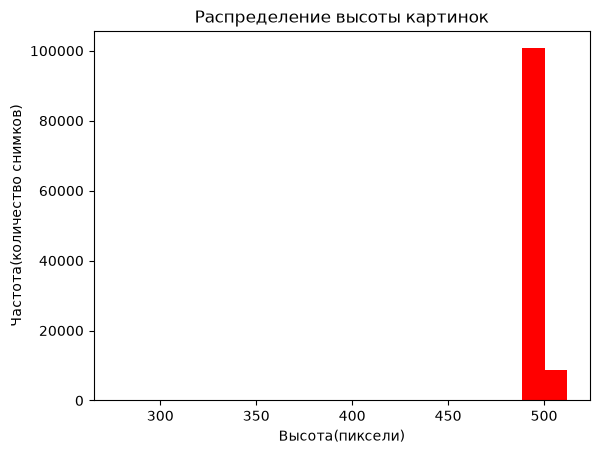

height
496    100648
512      8659
277         1
455         1
Name: count, dtype: int64


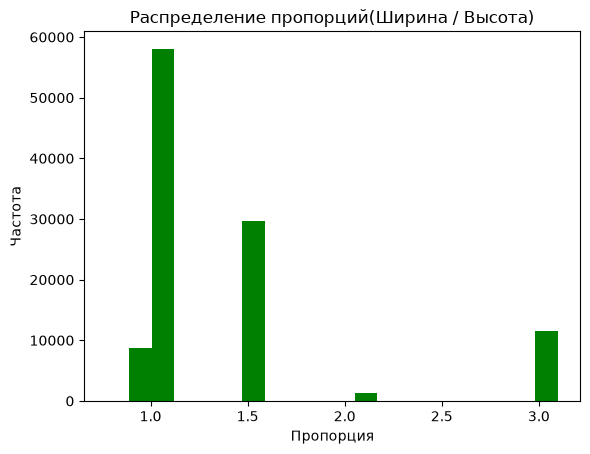

width  height
512    496       58037
768    496       29749
1536   496       11512
512    512        8659
1024   496        1329
384    496          21
642    277           1
900    455           1
dtype: int64


In [ ]:
#Строим графики количества каналов, ширины, высоты, распределение пропорций. 
import matplotlib.pyplot as plt

df['ratio'] = df['width'] / df['height']



df['channels'].value_counts().plot(kind = 'bar', color ='skyblue')
plt.title('Количество каналов')
plt.xlabel('Количесвто каналов')
plt.ylabel('Количество снимков')
plt.xticks(rotation=0)
plt.show()

df['width'].plot(kind = 'hist', bins = 20, color ='orange')
plt.title('Распределение ширины картинок')
plt.xlabel('Ширина(пиксели)')
plt.ylabel('Частота(количество снимков)')
plt.show()
print(df['width'].value_counts().head(10))

df['height'].plot(kind='hist', bins=20, color ='red')
plt.title('Распределение высоты картинок')
plt.xlabel('Высота(пиксели)')
plt.ylabel('Частота(количество снимков)')
plt.show()
print(df['height'].value_counts().head(10))

df['ratio'].plot(kind='hist', bins=20, color = 'green')
plt.title('Распределение пропорций(Ширина / Высота)')
plt.xlabel('Пропорция')
plt.ylabel('Частота')
plt.show()

# выводим количество снимков по уникальным разрешениям
# df.groupby - собирает картинки вместе с одинаковыми разрешениями, size() - считает их
sizec_count = df.groupby(['width', 'height']).size().sort_values(ascending=False)
print(sizec_count)




Всего 8 уникальных разрешений снимков. Наиболее частые: 512x496, 768x496, 1536x496, 512x512. Из этого можно сделать важный вывод: пропорции картинок различаются, надо привести к одному размеру, но обязательно сохранить анатомические пропорции на картинках.

У меня на графике на всех картинках 3 канала, у Виталия 1.  Я использовал библиотеку OpenCV, которая, если не указать ограничение, будет считывать 3 канала, даже если картинка черно-белая.

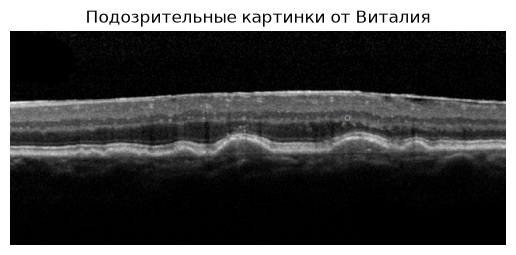

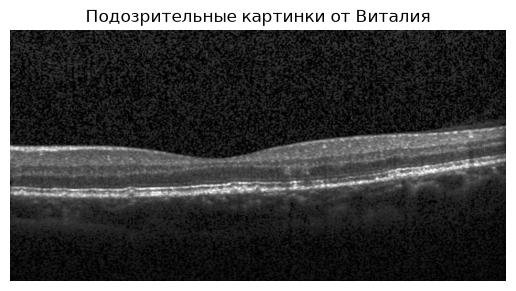

In [ ]:
#Выводим подозрительные картинки, которые подметил Виталий.
import matplotlib.pyplot as plt

#берем по 2 ширинам, которые встречаются тольку у этих картинок
weird_imgs = df[(df['width'] == 642) | (df['width'] == 900)]

for p in weird_imgs['image_path']: #проходимся по этим путям и выводим картинки
    img = plt.imread(p)
    plt.imshow(img, cmap='gray')
    plt.title('Подозрительные картинки от Виталия')
    plt.axis('off')
    plt.show()

Эти картинки схожи с другими.  Возможно, из-за необычного размера и 3 каналов, эти картинки были взяты уже из какого-то источника, их могли просто вырезать и сохранить.

1 картинка: похоже что обрезана как-то так, что центральной ямки не видно, но друзы есть и они отчетливы.

2 картинка: кажется, что бока обрезаны и видна большая центральная ямка. Друзы сложновато здесь различить. Возможно, что сам по себе класс друзы неоднороден.

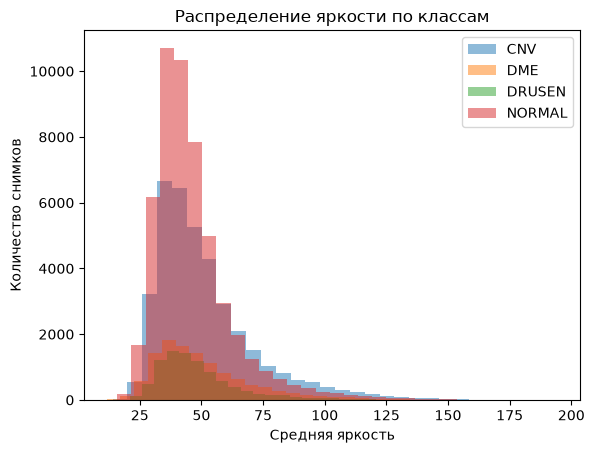

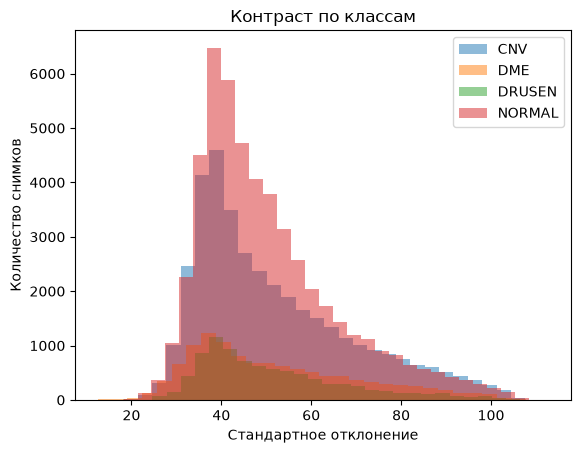

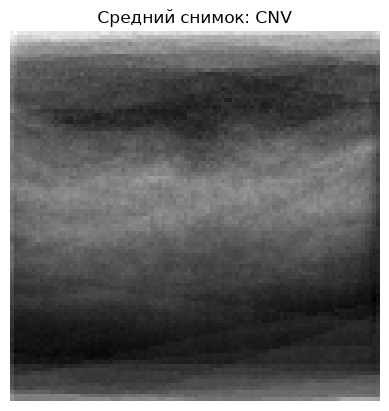

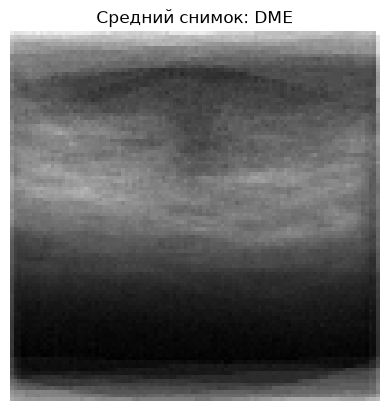

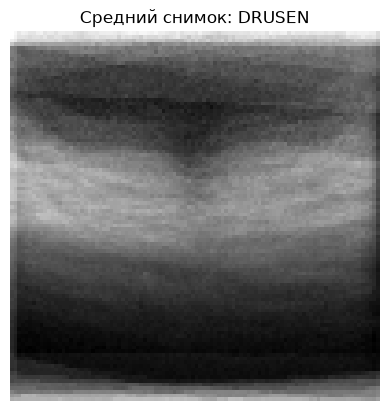

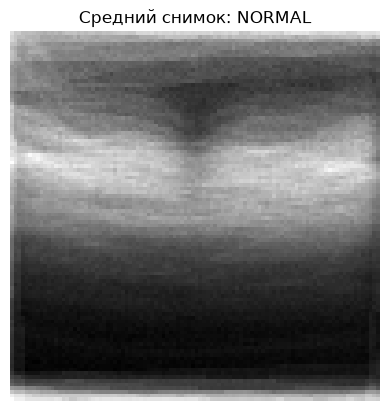

In [7]:
#Выводим графики яркости, контраста и средний снимок для каждого класса.
import cv2
import matplotlib.pyplot as plt
import numpy as np

bright = []
contrast = []

for b in df['image_path']:
    # b - путь к картинке, 0 - просим функцию прочитать картинку только в 1 канале
    img = cv2.imread(b, 0) 
    bright.append(img.mean())
    contrast.append(img.std())

df['bright'] = bright
df['contrast'] = contrast

#идем по каждому классу
for cls in df['label'].unique():
    subset = df[df['label'] == cls]  # оставляем строки текущего класса, берем все снимки класса
    plt.hist(subset['bright'], bins = 30, alpha=0.5, label=cls)

plt.title('Распределение яркости по классам')
plt.xlabel('Средняя яркость')
plt.ylabel('Количество снимков')
plt.legend()
plt.show()

for cls in df['label'].unique():
    subset = df[df['label'] == cls]
    plt.hist(subset['contrast'], bins=30, alpha=0.5, label=cls)

plt.title('Контраст по классам')
plt.xlabel('Стандартное отклонение')
plt.ylabel('Количество снимков')
plt.legend()
plt.show()

#Средний снимок
for cl in df['label'].unique():
    paths = df[df['label'] == cl].sample(50)['image_path']  # строки тек. класса, 50 случайных

    #проходимся по каждой из 50 картинок в ч/б и сжимаем 100 на 100 все в одинаковый размер.
    #Одинаковый размер нужен для усреднения
    imgs = [cv2.resize(cv2.imread(p, 0), (100, 100)) for p in paths]

    mean_img = np.mean(imgs, axis = 0)

    plt.imshow(mean_img, cmap = 'gray')
    plt.title(f'Средний снимок: {cl}')
    plt.axis('off')
    plt.show()

Распределение яркости и контраста по классам перекрывают друг друга.

Средний снимок изображения по каждому классу  должен демонстрировать визуальные различия между ними, но факту это сложно сделать, так как те или иные патологические признаки, характерные для того или иного заболевания неоднородны, и могут распологаться в разных участках сетчатки.

In [8]:
#Условия, по которым посчитаем количество выбросов

darker = df['bright']<20
brighter = df['bright']>130
wider = df['width'] > 1024

out = df[darker|brighter|wider]

out.to_csv('outliers.csv', index=False)
print(f'Выбросы: {len(out)}')

Выбросы: 12098


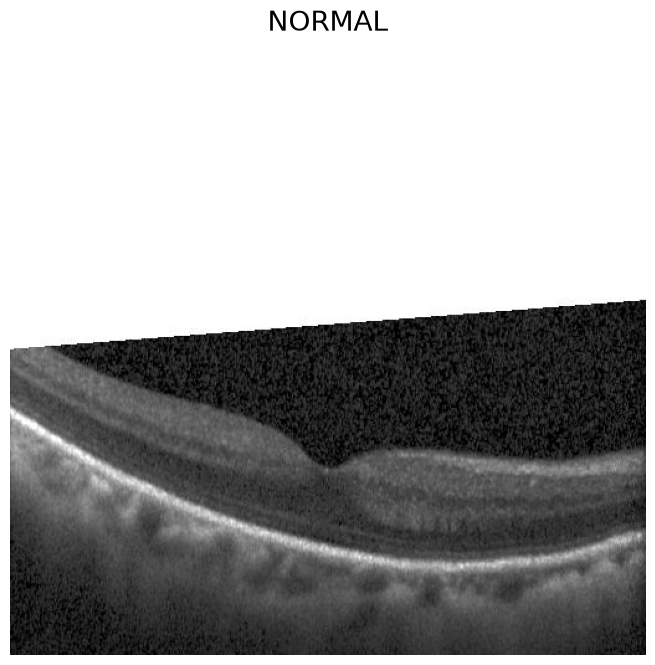

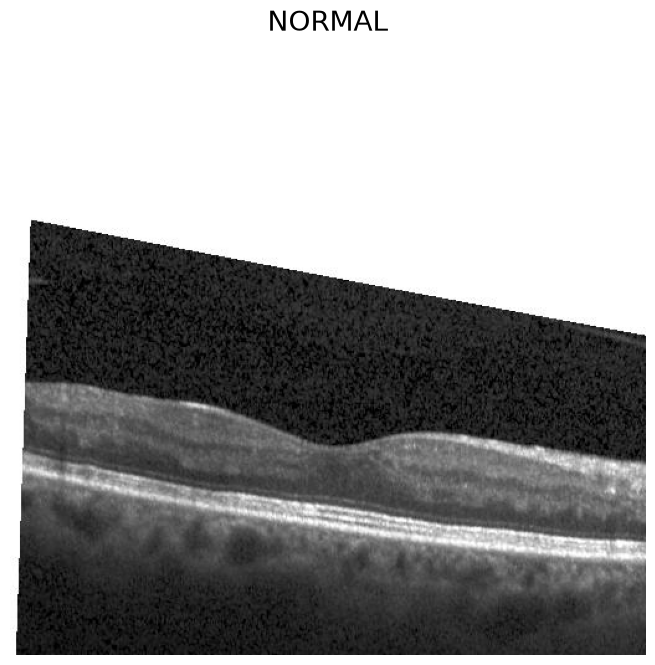

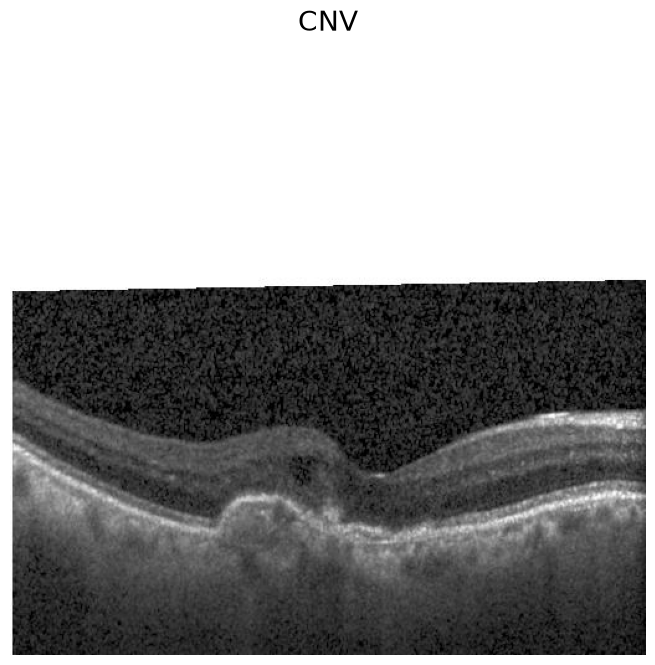

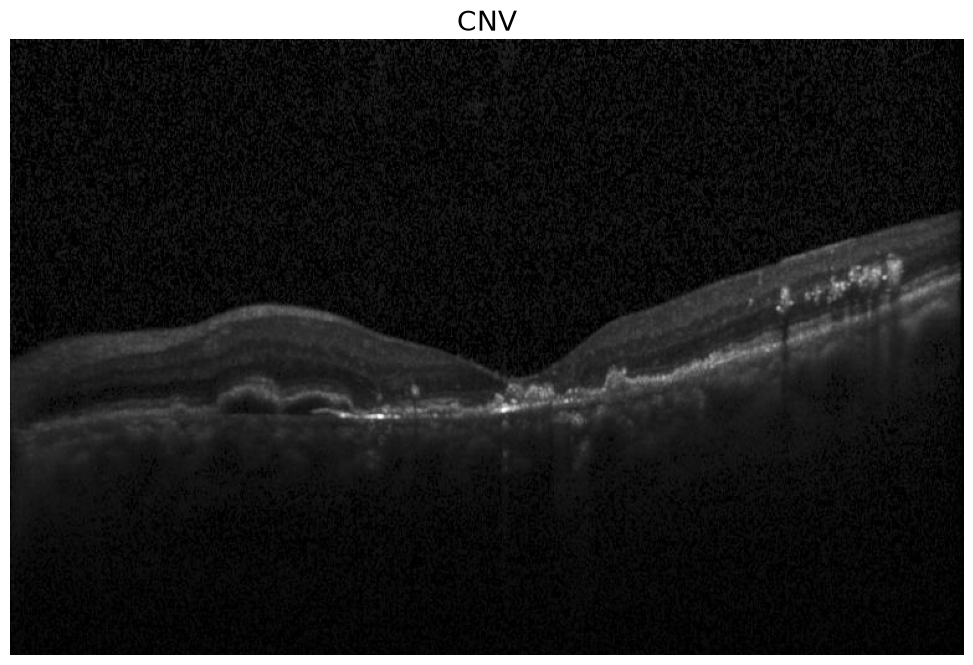

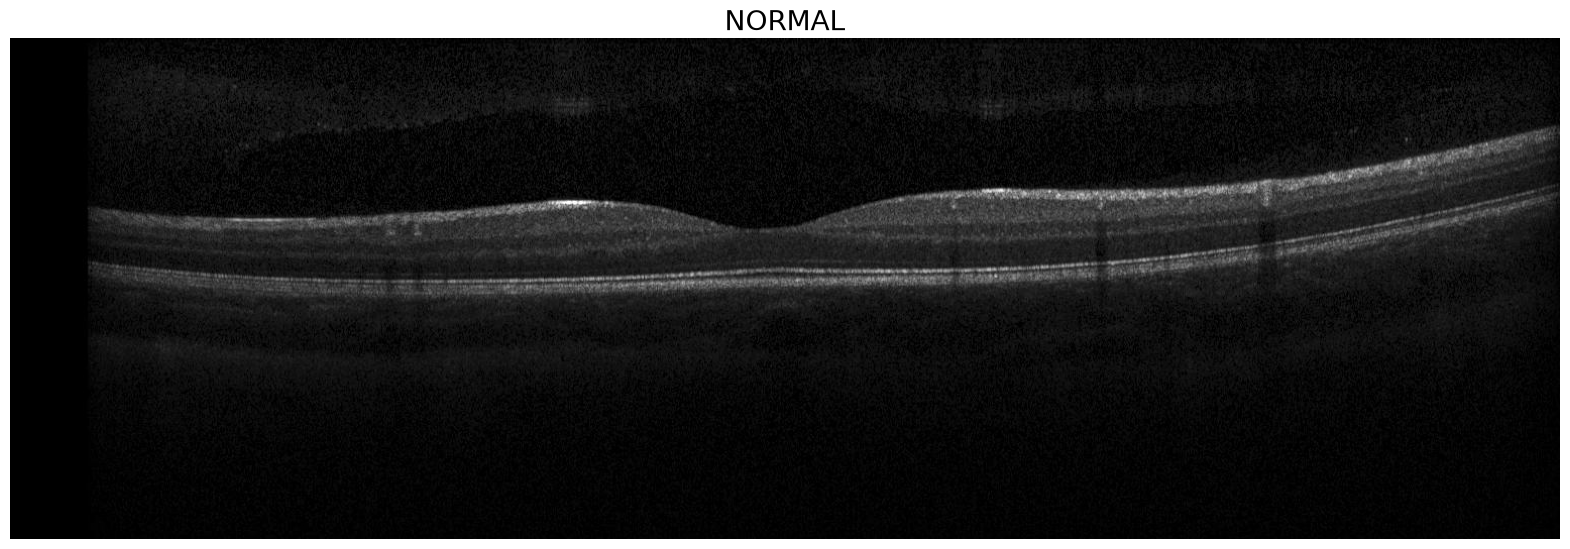

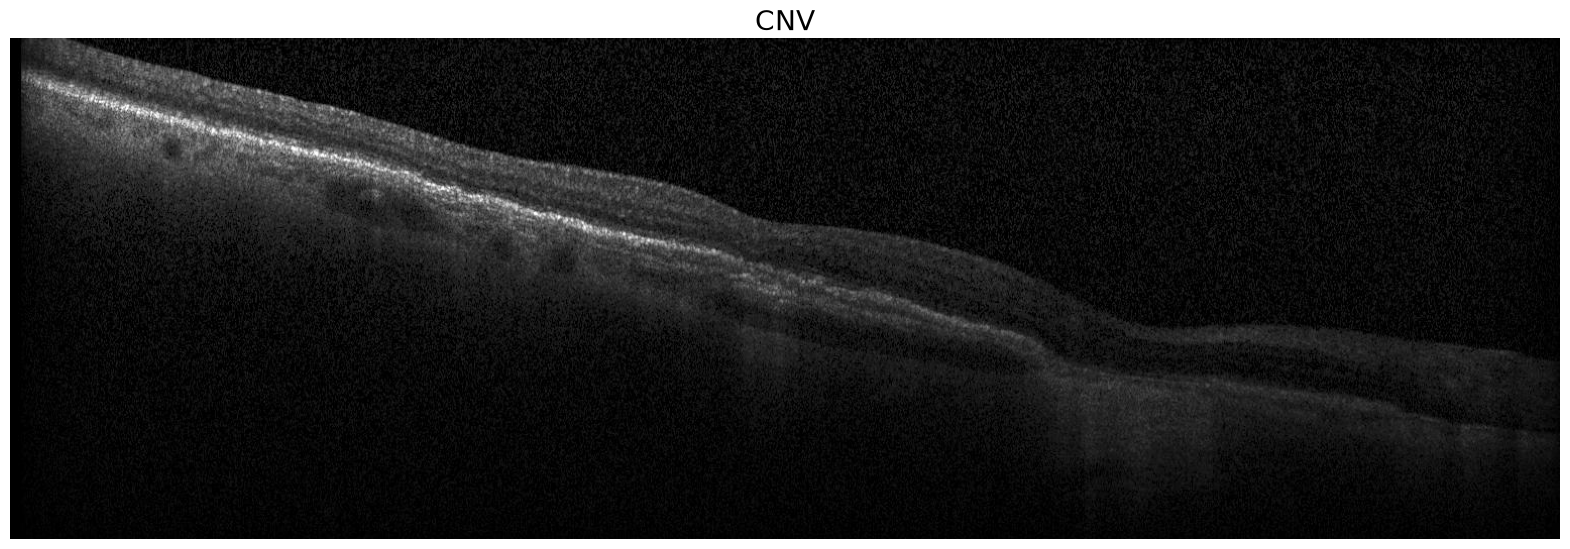

In [11]:
#Ручной просмотр выбросов
import pandas as pd
import matplotlib.pyplot as plt

outliers_df = pd.read_csv('outliers.csv')

#смотрим пересвеченные снимки
brighter_outliers = outliers_df[outliers_df['bright'] > 130].sample(3)



for i in range(3):

    row = brighter_outliers.iloc[i]
    img = plt.imread(row['image_path'])
    plt.figure(figsize=(20,8))
    plt.imshow(img, cmap='gray')
    plt.title(row['label'], fontsize=20)
    plt.axis('off')
    plt.show()

#смотрим наиболее затемненные снимки
darker_outliers = outliers_df[outliers_df['bright'] < 20].sample(3)


for i in range(3):

    row = darker_outliers.iloc[i]
    img = plt.imread(row['image_path'])
    plt.figure(figsize=(20,8))
    plt.imshow(img, cmap='gray')
    plt.title(row['label'], fontsize=20)
    plt.axis('off')
    plt.show()    

Ручной просмотр снимков:

*В ходе просмотра снимков ошибок в разметке не выявил, даже с такой яркостью на выбросах можно определить класс.

*Однако, на темных и ярких снимках заметна зернистоть, иногда крайне значительная.
 

In [ ]:
#Считаем mean и std яркости
mean_val = df['bright'].mean()/255.0
std_val = df['bright'].std()/255.0

print(f'mean: {mean_val.round(4)}')
print(f'std: {std_val.round(4)}')


mean: 0.1909
std: 0.0728
